In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV


In [2]:
df = pd.read_parquet("clean.parquet")
df

,date,serial_number,model,failure,smart_5_raw,smart_9_raw,smart_187_raw,smart_188_raw,smart_194_raw,smart_197_raw,smart_198_raw
342349,2024-01-01,ZHZ07RNQ,ST12000NM0008,0,0.0,36643.0,0.0,0.0,27.0,0.0,0.0
536522,2024-01-02,ZHZ07RNQ,ST12000NM0008,0,0.0,36674.0,0.0,0.0,27.0,0.0,0.0
633467,2024-01-03,ZHZ07RNQ,ST12000NM0008,0,0.0,36689.0,0.0,0.0,27.0,0.0,0.0
167701,2024-01-04,ZHZ07RNQ,ST12000NM0008,0,0.0,36721.0,0.0,0.0,27.0,0.0,0.0
322899,2024-01-05,ZHZ07RNQ,ST12000NM0008,0,0.0,36736.0,0.0,0.0,27.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
1745537,2024-03-27,ZL00RAMH,ST12000NM0008,0,0.0,5018.0,0.0,0.0,33.0,0.0,0.0
290011,2024-03-28,ZL00RAMH,ST12000NM0008,0,0.0,5034.0,0.0,0.0,32.0,0.0,0.0
212488,2024-03-29,ZL00RAMH,ST12000NM0008,0,0.0,5065.0,0.0,0.0,33.0,0.0,0.0
1629133,2024-03-30,ZL00RAMH,ST12000NM0008,0,0.0,5080.0,0.0,0.0,32.0,0.0,0.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
Index: 1766030 entries, 342349 to 1571028
Data columns (total 11 columns):
 #   Column         Dtype         
---  ------         -----         
 0   date           datetime64[us]
 1   serial_number  str           
 2   model          str           
 3   failure        int64         
 4   smart_5_raw    float64       
 5   smart_9_raw    float64       
 6   smart_187_raw  float64       
 7   smart_188_raw  float64       
 8   smart_194_raw  float64       
 9   smart_197_raw  float64       
 10  smart_198_raw  float64       
dtypes: datetime64[us](1), float64(7), int64(1), str(2)
memory usage: 197.1 MB


In [4]:
df.head()

,date,serial_number,model,failure,smart_5_raw,smart_9_raw,smart_187_raw,smart_188_raw,smart_194_raw,smart_197_raw,smart_198_raw
342349,2024-01-01,ZHZ07RNQ,ST12000NM0008,0,0.0,36643.0,0.0,0.0,27.0,0.0,0.0
536522,2024-01-02,ZHZ07RNQ,ST12000NM0008,0,0.0,36674.0,0.0,0.0,27.0,0.0,0.0
633467,2024-01-03,ZHZ07RNQ,ST12000NM0008,0,0.0,36689.0,0.0,0.0,27.0,0.0,0.0
167701,2024-01-04,ZHZ07RNQ,ST12000NM0008,0,0.0,36721.0,0.0,0.0,27.0,0.0,0.0
322899,2024-01-05,ZHZ07RNQ,ST12000NM0008,0,0.0,36736.0,0.0,0.0,27.0,0.0,0.0


In [5]:
df.isnull().sum()

date             0
serial_number    0
model            0
failure          0
smart_5_raw      0
smart_9_raw      0
smart_187_raw    0
smart_188_raw    0
smart_194_raw    0
smart_197_raw    0
smart_198_raw    0
dtype: int64

In [6]:
failure_count = df["failure"].value_counts().sort_index()
failure_percentage = df["failure"].value_counts(normalize=True).sort_index() * 100

print(f"Failure counts: {failure_count}")
print(f"Failure percentage: {failure_percentage}.round(3)")


Failure counts: failure
0    1765886
1        144
Name: count, dtype: int64
Failure percentage: failure
0    99.991846
1     0.008154
Name: proportion, dtype: float64.round(3)


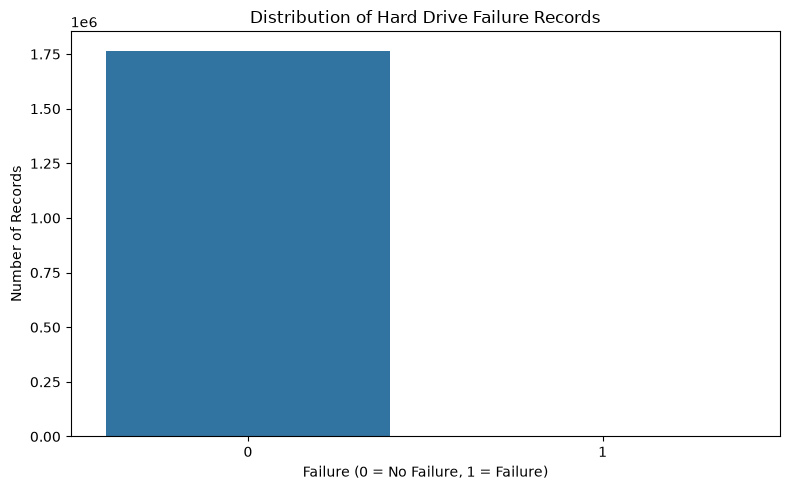

In [7]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="failure")
plt.title("Distribution of Hard Drive Failure Records")
plt.xlabel("Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

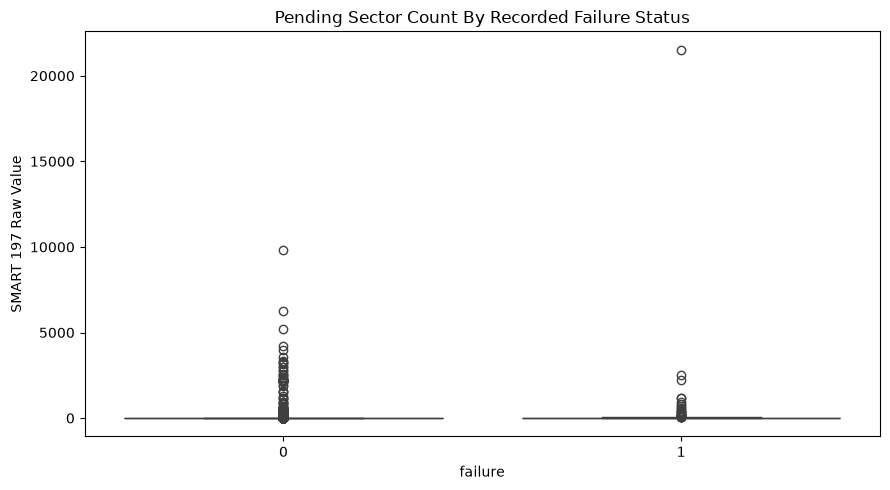

In [8]:
plt.figure(figsize=(9,5))
sns.boxplot(
    data = df,
    x= "failure",
    y= "smart_197_raw"
)
plt.title("Pending Sector Count By Recorded Failure Status")
plt.ylabel("SMART 197 Raw Value")
plt.tight_layout()
plt.show()


In [9]:
print("Earliest date:", df["date"].min())
print("Latest date:", df["date"].max())

print("Unique drives:", df["serial_number"].nunique())
print("Unique models:", df["model"].nunique())

Earliest date: 2024-01-01 00:00:00
Latest date: 2024-03-31 00:00:00
Unique drives: 19511
Unique models: 1


In [10]:
failed_rows = df[df["failure"] == 1] 
failed_rows

,date,serial_number,model,failure,smart_5_raw,smart_9_raw,smart_187_raw,smart_188_raw,smart_194_raw,smart_197_raw,smart_198_raw
1274745,2024-03-22,ZHZ0N19K,ST12000NM0008,1,2264.0,38642.0,41.0,0.000000e+00,33.0,352.0,352.0
1545996,2024-03-25,ZHZ0NN8H,ST12000NM0008,1,11544.0,38671.0,145.0,4.298310e+09,45.0,8.0,8.0
1312982,2024-01-19,ZHZ0RH56,ST12000NM0008,1,15728.0,37084.0,261.0,6.553700e+04,32.0,0.0,0.0
729785,2024-02-20,ZHZ2KM60,ST12000NM0008,1,8.0,37867.0,11.0,0.000000e+00,26.0,408.0,408.0
1661967,2024-01-09,ZHZ39PD5,ST12000NM0008,1,0.0,36842.0,32.0,6.553700e+04,27.0,48.0,48.0
...,...,...,...,...,...,...,...,...,...,...,...
1368733,2024-03-08,ZL005DHM,ST12000NM0008,1,0.0,31097.0,0.0,0.000000e+00,35.0,0.0,0.0
1134741,2024-02-13,ZL005DJV,ST12000NM0008,1,0.0,28549.0,0.0,0.000000e+00,29.0,0.0,0.0
1057512,2024-02-16,ZL005DNR,ST12000NM0008,1,24.0,30410.0,56.0,3.932220e+05,31.0,208.0,208.0
1093530,2024-02-06,ZL005DPD,ST12000NM0008,1,64.0,25860.0,41.0,0.000000e+00,27.0,0.0,0.0


In [11]:
failed_rows[[
    "date", "serial_number", "model", "failure"
 ]].head(10)

,date,serial_number,model,failure
1274745,2024-03-22,ZHZ0N19K,ST12000NM0008,1
1545996,2024-03-25,ZHZ0NN8H,ST12000NM0008,1
1312982,2024-01-19,ZHZ0RH56,ST12000NM0008,1
729785,2024-02-20,ZHZ2KM60,ST12000NM0008,1
1661967,2024-01-09,ZHZ39PD5,ST12000NM0008,1
1312993,2024-01-19,ZHZ3F000,ST12000NM0008,1
769378,2024-02-23,ZHZ3NC25,ST12000NM0008,1
789333,2024-02-27,ZHZ3NQTA,ST12000NM0008,1
1624667,2024-03-30,ZHZ3P3GX,ST12000NM0008,1
873888,2024-02-19,ZHZ3PMB1,ST12000NM0008,1


In [12]:
#count failure per drive
failures_per_drive = (
    df[df["failure"] == 1]
    .groupby("serial_number")
    .size()
    .sort_values(ascending=False)
)

print("Number of unique failed drives:", len(failures_per_drive))
print("Failure records per drive:", failures_per_drive.value_counts().sort_index())
print("Drives with the most failure records:", failures_per_drive.head(10))

Number of unique failed drives: 144
Failure records per drive: 1    144
Name: count, dtype: int64
Drives with the most failure records: serial_number
ZHZ0N19K    1
ZHZ0NN8H    1
ZHZ635WW    1
ZHZ63CJW    1
ZHZ63E8D    1
ZHZ63E90    1
ZHZ63EM4    1
ZHZ65823    1
ZHZ659XR    1
ZHZ65ECR    1
dtype: int64


In [13]:
#sort records in order of time
df = df.sort_values(["serial_number", "date"]).copy()

#show the first and last observation for a sample of failed drives
failed_serials = df.loc[df["failure"] == 1, "serial_number"].unique()

sample_serials = failed_serials[:5]

display(
    df[df["serial_number"].isin(sample_serials)]
.groupby("serial_number")
.agg(
    first_obs=("date", "min"),
    last_obs=("date", "max"),
    number_of_observations= ("date", "size"),
    failure_records= ("failure", "sum")
)
)


,first_obs,last_obs,number_of_observations,failure_records
serial_number,,,,
ZHZ0N19K,2024-01-01,2024-03-22,82,1
ZHZ0NN8H,2024-01-01,2024-03-25,85,1
ZHZ0RH56,2024-01-01,2024-01-19,19,1
ZHZ2KM60,2024-01-01,2024-02-20,51,1
ZHZ39PD5,2024-01-01,2024-01-09,9,1


In [14]:
#get the final observation for every drive
last_obs = (
    df.sort_values("date")
    .groupby("serial_number")
    .tail(1)
)

print("Total unique drives:", df["serial_number"].nunique())
print("Final observation labels:", last_obs["failure"].value_counts())
print("Final observation labelled as failures:")
display(
    last_obs.loc[
        last_obs["failure"] == 1,
        ["date","serial_number","model","failure"]
    ].head(10)
)

Total unique drives: 19511
Final observation labels: failure
0    19370
1      141
Name: count, dtype: int64
Final observation labelled as failures:


,date,serial_number,model,failure
332984,2024-01-01,ZHZ4VQ82,ST12000NM0008,1
541462,2024-01-02,ZHZ6CF50,ST12000NM0008,1
639854,2024-01-03,ZHZ6D3QP,ST12000NM0008,1
632768,2024-01-03,ZHZ3X2LK,ST12000NM0008,1
156999,2024-01-04,ZHZ4MKHN,ST12000NM0008,1
169376,2024-01-04,ZHZ50M55,ST12000NM0008,1
325364,2024-01-05,ZHZ50R4E,ST12000NM0008,1
325405,2024-01-05,ZHZ50M4L,ST12000NM0008,1
311677,2024-01-05,ZHZ4VWV3,ST12000NM0008,1
117304,2024-01-06,ZHZ511SW,ST12000NM0008,1


In [15]:
#prepare features for training
smart_features = [
    col for col in df.columns
    if col.startswith("smart_") and col.endswith("_raw")
]

smart_features

['smart_5_raw',
 'smart_9_raw',
 'smart_187_raw',
 'smart_188_raw',
 'smart_194_raw',
 'smart_197_raw',
 'smart_198_raw']

In [16]:
X = df[smart_features]
y = df["failure"]

In [17]:
#Ensure date is stored as datetime
df["date"] = pd.to_datetime(df["date"])

#sort observations chronologically
df = df.sort_values("date").reset_index(drop=True)

#Define the chronological split point
split_index = int(len(df)*0.8)
split_date = df.loc[split_index, "date"]

#Separate earlier and later observations
train_df = df[df["date"] < split_date].copy()
test_df = df[df["date"] >= split_date].copy()

In [18]:
X_train = train_df[smart_features]
y_train = train_df["failure"]

X_test = test_df[smart_features]
y_test = test_df["failure"]

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['smart_5_raw','smart_9_raw','smart_187_raw',...,'smart_194_raw', 'smart_197_raw','smart_198_raw']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_val

In [19]:
y_pred = model.predict(X_test)

In [20]:
#confusion matrix
print("Confusion Matrix:", confusion_matrix(y_test,y_pred))

Confusion Matrix: [[367998     19]
 [    23      2]]


In [21]:
print("Classification report:", classification_report(y_test,y_pred,zero_division=0))

Classification report:               precision    recall  f1-score   support

           0       1.00      1.00      1.00    368017
           1       0.10      0.08      0.09        25

    accuracy                           1.00    368042
   macro avg       0.55      0.54      0.54    368042
weighted avg       1.00      1.00      1.00    368042



In [22]:
from sklearn.metrics import average_precision_score


In [23]:

df_future = pd.read_parquet("clean.parquet")

print(type(df_future))

<class 'pandas.DataFrame'>


In [24]:

#get the model's probability estimates for class 1
y_proba = model.predict_proba(X_test)[:, 1]

#Evaluate ranking performance for the rare failure class
pr_auc = average_precision_score(y_test, y_proba)

print("Average precision (PR-AUC):", round(pr_auc, 4))

Average precision (PR-AUC): 0.0155


In [25]:
df_future = df.copy()

#sorting each drive's observations chronologically
df_future = df_future.sort_values(
    ["serial_number", "date"]
).reset_index(drop=True)
df_future

,date,serial_number,model,failure,smart_5_raw,smart_9_raw,smart_187_raw,smart_188_raw,smart_194_raw,smart_197_raw,smart_198_raw
0,2024-01-01,ZHZ07RNQ,ST12000NM0008,0,0.0,36643.0,0.0,0.0,27.0,0.0,0.0
1,2024-01-02,ZHZ07RNQ,ST12000NM0008,0,0.0,36674.0,0.0,0.0,27.0,0.0,0.0
2,2024-01-03,ZHZ07RNQ,ST12000NM0008,0,0.0,36689.0,0.0,0.0,27.0,0.0,0.0
3,2024-01-04,ZHZ07RNQ,ST12000NM0008,0,0.0,36721.0,0.0,0.0,27.0,0.0,0.0
4,2024-01-05,ZHZ07RNQ,ST12000NM0008,0,0.0,36736.0,0.0,0.0,27.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
1766025,2024-03-27,ZL00RAMH,ST12000NM0008,0,0.0,5018.0,0.0,0.0,33.0,0.0,0.0
1766026,2024-03-28,ZL00RAMH,ST12000NM0008,0,0.0,5034.0,0.0,0.0,32.0,0.0,0.0
1766027,2024-03-29,ZL00RAMH,ST12000NM0008,0,0.0,5065.0,0.0,0.0,33.0,0.0,0.0
1766028,2024-03-30,ZL00RAMH,ST12000NM0008,0,0.0,5080.0,0.0,0.0,32.0,0.0,0.0


In [26]:
#create next observation failure target
data = pd.read_parquet("clean.parquet")
data["date"] = pd.to_datetime(data["date"])
data = data.sort_values(["serial_number", "date"])

data["next_failure"] = (
    data.groupby("serial_number")["failure"].shift(-1)
)
    
data = data.dropna(subset=["next_failure"]).copy()
data["next_failure"] = data["next_failure"].astype(int)

print(data["next_failure"].value_counts())

next_failure
0    1746377
1        142
Name: count, dtype: int64


In [27]:
#features for chronological training
smart_features = [
    col for col in data.columns
    if col.startswith("smart_") and col.endswith("_raw")
]
print("SMART featrures:", smart_features)

SMART featrures: ['smart_5_raw', 'smart_9_raw', 'smart_187_raw', 'smart_188_raw', 'smart_194_raw', 'smart_197_raw', 'smart_198_raw']


In [28]:
print(data["next_failure"].value_counts())
print(data["next_failure"].value_counts(normalize=True).round(6))

next_failure
0    1746377
1        142
Name: count, dtype: int64
next_failure
0    0.999919
1    0.000081
Name: proportion, dtype: float64


In [29]:
#Earlier dates will train and later dates will test
split_date = data["date"].quantile(0.80)

train_df = data[data["date"] < split_date].copy()
test_df = data[data["date"] >= split_date].copy()

X_train = train_df[smart_features]
y_train = train_df["next_failure"]

X_test = test_df[smart_features]
y_test = test_df["next_failure"]



In [ ]:
param_grid = {
    "classifier__n_estimators": [100,200],
    "classifier__max_depth": [10,20]
}

grid_search = GridSearchCV(
    model,
    param_grid,
    cv=3,
    scoring="recall",
    n_jobs=-1
)

grid_search.fit(X_train,y_train)
print("Best Parameters:", grid_search.best_params_)
model = grid_search.best_estimator_

In [ ]:
y_pred = model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test,y_pred))

print("Classification Report:")
print(classification_report(y_test,y_pred, zero_division=0))

Confusion Matrix:
[[364643   3366]
 [    13     12]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00    368009
           1       0.00      0.48      0.01        25

    accuracy                           0.99    368034
   macro avg       0.50      0.74      0.50    368034
weighted avg       1.00      0.99      1.00    368034



In [ ]:
print("Best parameters:", grid_search.best_params_)

Best parameters: {'classifier__max_depth': 10, 'classifier__n_estimators': 200}


In [ ]:
import joblib

joblib.dump(model, "drive_failure_prediction_model.pkl")

['drive_failure_prediction_model.pkl']